In [1]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

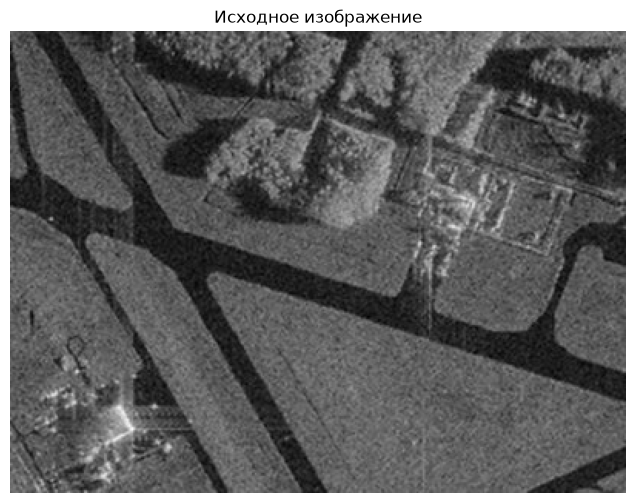

In [3]:
## Пункт 1. Загрузка исходного изображения

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

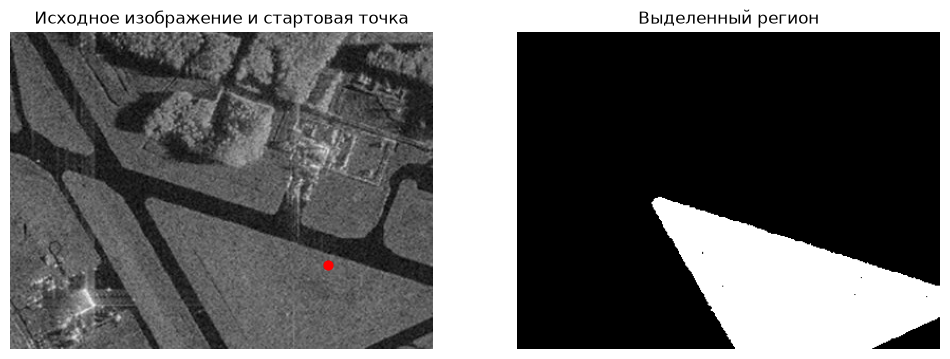

In [4]:
## Пункт 2. Разрастание региона для выделения газона

seed_x = 300
seed_y = 220
threshold = 45

visited = np.zeros_like(image_gray, dtype=np.uint8)
region = np.zeros_like(image_gray, dtype=np.uint8)

seed_value = int(image_gray[seed_y, seed_x])

stack = [(seed_x, seed_y)]

while stack:
    x, y = stack.pop()

    if x < 0 or x >= image_gray.shape[1] or y < 0 or y >= image_gray.shape[0]:
        continue

    if visited[y, x] == 1:
        continue

    visited[y, x] = 1

    pixel_value = int(image_gray[y, x])

    if abs(pixel_value - seed_value) <= threshold:
        region[y, x] = 255

        stack.append((x + 1, y))
        stack.append((x - 1, y))
        stack.append((x, y + 1))
        stack.append((x, y - 1))

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.scatter(seed_x, seed_y, c='red', s=40)
plt.title('Исходное изображение и стартовая точка')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(region, cmap='gray')
plt.title('Выделенный регион')
plt.axis('off')

plt.show()

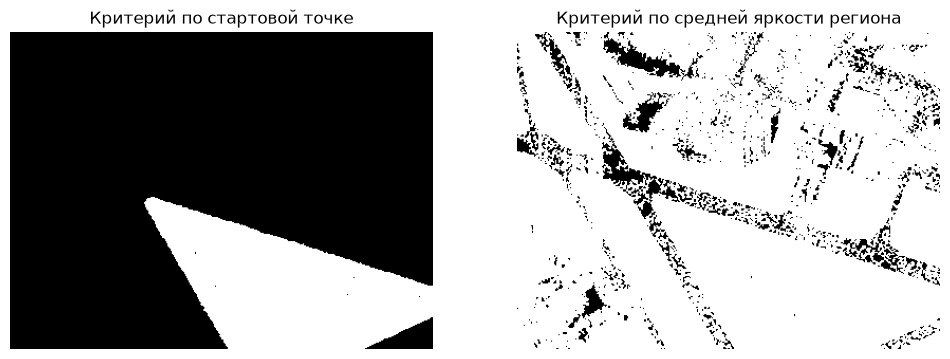

Вывод:
Критерий по стартовой точке лучше выделяет заданный участок газона.
Критерий по средней яркости региона захватывает лишние области изображения.


In [5]:
## Пункт 3. Сравнение двух критериев однородности

seed_x = 300
seed_y = 220
threshold = 45

visited_avg = np.zeros_like(image_gray, dtype=np.uint8)
region_avg = np.zeros_like(image_gray, dtype=np.uint8)

region_avg[seed_y, seed_x] = 255

stack = [(seed_x, seed_y)]

while stack:
    x, y = stack.pop()

    if x < 0 or x >= image_gray.shape[1] or y < 0 or y >= image_gray.shape[0]:
        continue

    if visited_avg[y, x] == 1:
        continue

    visited_avg[y, x] = 1

    region_pixels = image_gray[region_avg > 0]
    mean_value = np.mean(region_pixels)

    pixel_value = int(image_gray[y, x])

    if abs(pixel_value - mean_value) <= threshold:
        region_avg[y, x] = 255

        stack.append((x + 1, y))
        stack.append((x - 1, y))
        stack.append((x, y + 1))
        stack.append((x, y - 1))

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(region, cmap='gray')
plt.title('Критерий по стартовой точке')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(region_avg, cmap='gray')
plt.title('Критерий по средней яркости региона')
plt.axis('off')

plt.show()

print('Вывод:')
print('Критерий по стартовой точке лучше выделяет заданный участок газона.')
print('Критерий по средней яркости региона захватывает лишние области изображения.')

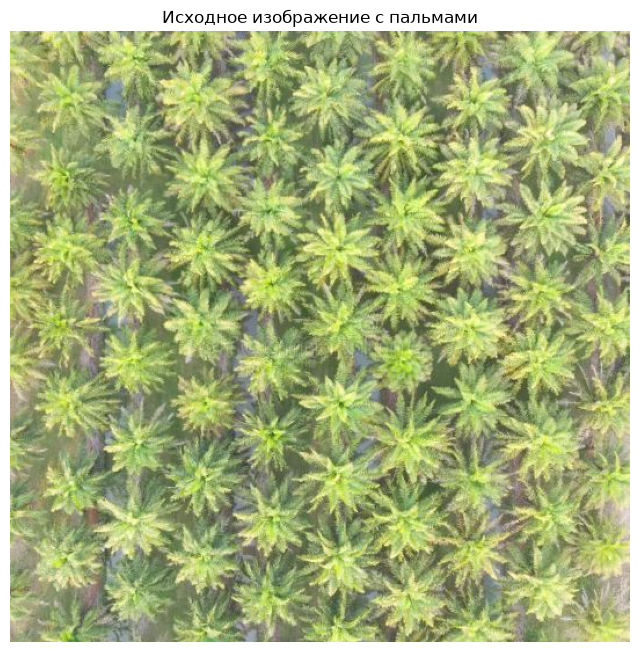

In [6]:
## Пункт 4. Загрузка изображения с пальмами

palm_image = cv2.imread('palm_1.JPG')
palm_rgb = cv2.cvtColor(palm_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(palm_rgb)
plt.title('Исходное изображение с пальмами')
plt.axis('off')
plt.show()

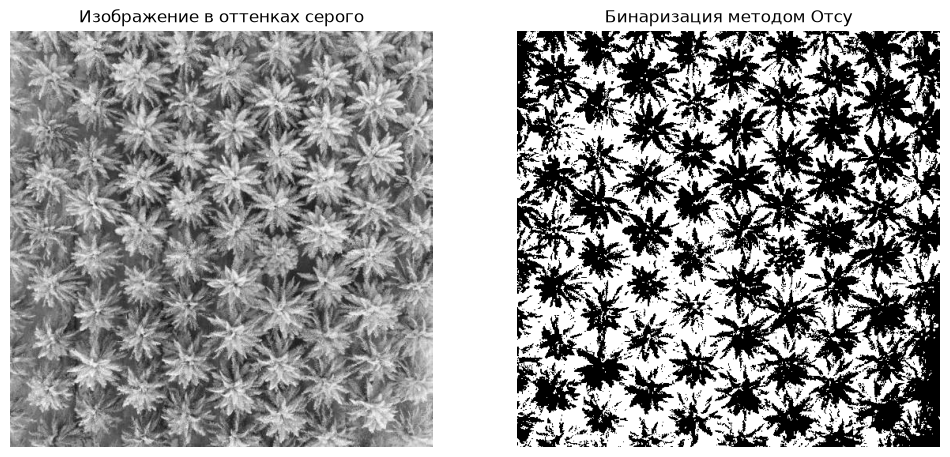

In [7]:
## Пункт 5. Бинаризация изображения с пальмами

palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)

ret, palm_thresh = cv2.threshold(
    palm_gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(palm_gray, cmap='gray')
plt.title('Изображение в оттенках серого')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(palm_thresh, cmap='gray')
plt.title('Бинаризация методом Отсу')
plt.axis('off')

plt.show()

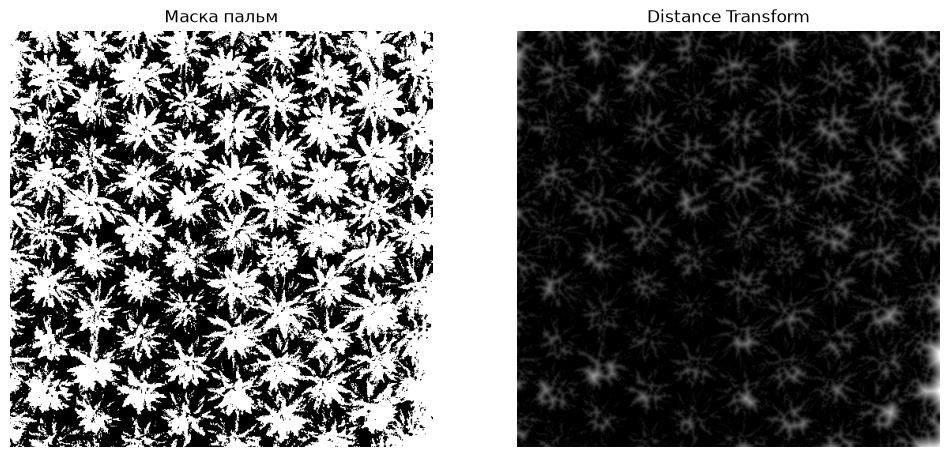

In [8]:
## Пункт 6. Distance Transform для пальм

palm_mask = cv2.bitwise_not(palm_thresh)

dist = cv2.distanceTransform(
    palm_mask,
    cv2.DIST_L2,
    5
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(palm_mask, cmap='gray')
plt.title('Маска пальм')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(dist, cmap='gray')
plt.title('Distance Transform')
plt.axis('off')

plt.show()

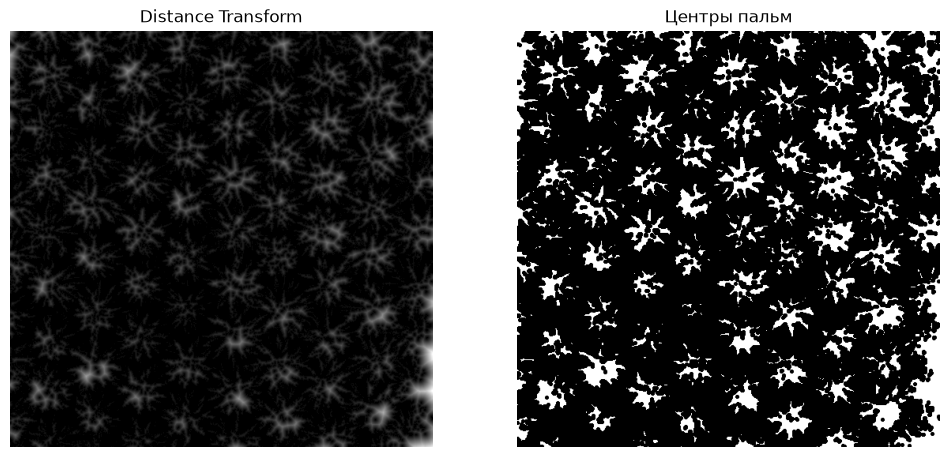

In [9]:
## Пункт 7. Выделение центров пальм

_, sure_fg = cv2.threshold(
    dist,
    0.13 * dist.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = np.uint8(sure_fg)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(dist, cmap='gray')
plt.title('Distance Transform')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sure_fg, cmap='gray')
plt.title('Центры пальм')
plt.axis('off')

plt.show()

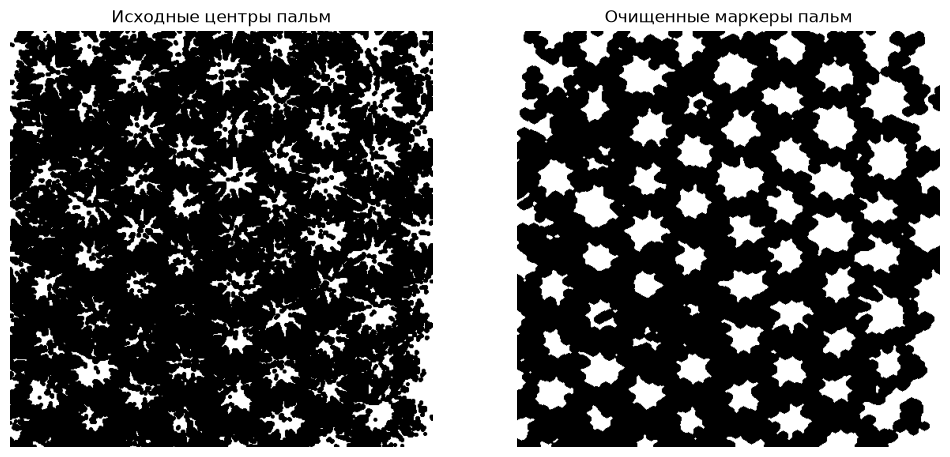

Количество начальных маркеров: 113


In [10]:
## Пункт 8. Подготовка маркеров для Watershed

kernel_close = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (7, 7)
)

markers_clean = cv2.morphologyEx(
    sure_fg,
    cv2.MORPH_CLOSE,
    kernel_close,
    iterations=2
)

kernel_open = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (3, 3)
)

markers_clean = cv2.morphologyEx(
    markers_clean,
    cv2.MORPH_OPEN,
    kernel_open,
    iterations=1
)

num_labels, markers = cv2.connectedComponents(markers_clean)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(sure_fg, cmap='gray')
plt.title('Исходные центры пальм')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(markers_clean, cmap='gray')
plt.title('Очищенные маркеры пальм')
plt.axis('off')

plt.show()

print('Количество начальных маркеров:', num_labels - 1)

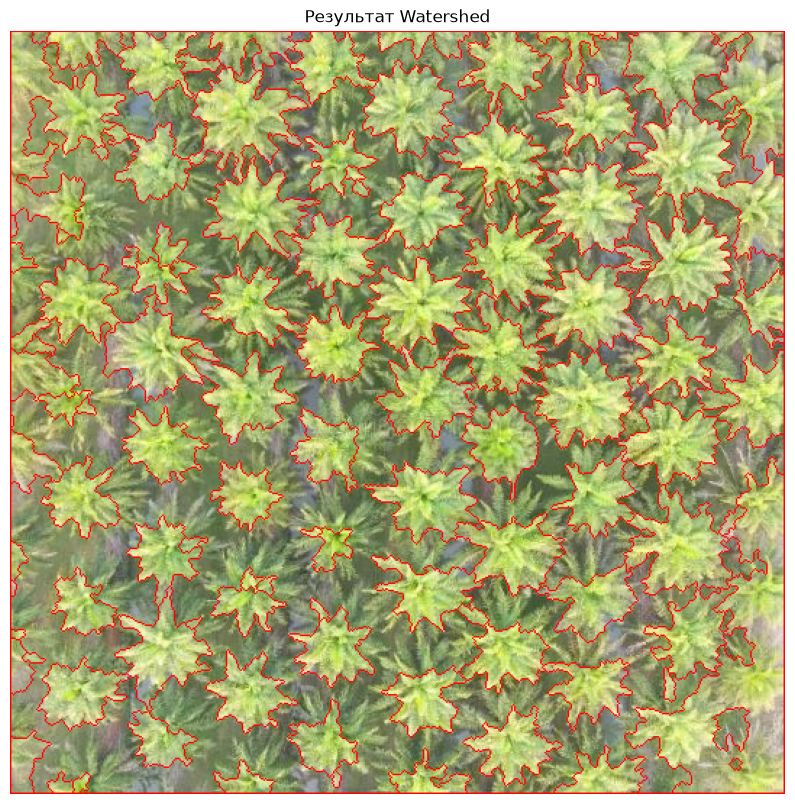

Количество найденных пальм: 113


In [11]:
## Пункт 9. Watershed и подсчёт пальм

kernel = np.ones((3, 3), np.uint8)

sure_bg = cv2.dilate(
    palm_mask,
    kernel,
    iterations=2
)

unknown = cv2.subtract(sure_bg, markers_clean)

num_labels, markers = cv2.connectedComponents(markers_clean)

markers = markers + 1
markers[unknown == 255] = 0

watershed_markers = cv2.watershed(
    palm_image.copy(),
    markers
)

result = palm_rgb.copy()

result[watershed_markers == -1] = [255, 0, 0]

labels = np.unique(watershed_markers)
palm_labels = labels[labels > 1]

palm_count = len(palm_labels)

plt.figure(figsize=(10, 10))
plt.imshow(result)
plt.title('Результат Watershed')
plt.axis('off')
plt.show()

print('Количество найденных пальм:', palm_count)

In [12]:
## Пункт 10. Итог

print('Итог работы:')
print('1. Методом разрастания регионов был выделен участок газона.')
print('2. Для выделения газона подобраны параметры: seed = (300, 220), threshold = 45.')
print('3. Были сравнены два критерия однородности: по стартовой точке и по средней яркости региона.')
print('4. Критерий по стартовой точке лучше выделил заданный участок газона.')
print('5. Для изображения с пальмами применены Distance Transform и Watershed.')
print(f'6. Найденное количество пальм: {palm_count}.')

Итог работы:
1. Методом разрастания регионов был выделен участок газона.
2. Для выделения газона подобраны параметры: seed = (300, 220), threshold = 45.
3. Были сравнены два критерия однородности: по стартовой точке и по средней яркости региона.
4. Критерий по стартовой точке лучше выделил заданный участок газона.
5. Для изображения с пальмами применены Distance Transform и Watershed.
6. Найденное количество пальм: 113.
